# Supplementary Fig. 6a: sorting accuracy as a function of the delta time

**author**: laquitainesteeve@gmail.com

**purpose**: reproduce panel a of Supplementary Fig. 6: effect of the delta time (the time window around each ground truth spike within which a sorted spike and a ground truth spike coincide) on the sorting accuracy, for the first 10 minutes of the simulation of the Neuropixels recording in the spontaneous regime sorted with Kilosort4 on the Tesla V100 (the paper's run). Sorting accuracy is the proportion of ground truth units that are well detected (best agreement score with a sorted unit of at least 0.8). Source data and svg are saved in figures/8_source_data/supp_fig6a/.

**method (as in the paper's notebook supp_fig6_A_adj_delta_time.ipynb)**: for each delta time between 0 and 29.9 ms (step 0.1 ms), the first 10 minutes of the ground truth are compared with the sorting (`spikeinterface.comparison.compare_sorter_to_ground_truth`, `exhaustive_gt=True`) and the sorting accuracy is calculated (`src/nodes/metrics/delta_time.py`). The dotted lines mark the delta time used in all the analyses of the paper (1.3 ms) and the accuracy at that delta time; the delta time that maximizes the accuracy of this sorting (1.8 ms) is printed below.

In [1]:
# SETUP PACKAGES
import os
import warnings
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
warnings.simplefilter(action="ignore")

# SET PROJECT PATH
PROJ_PATH = "/home/steeve/steeve/epfl/code/spikebias"
os.chdir(PROJ_PATH)
from src.nodes.metrics import delta_time

# DATA: first 10 minutes of the simulation of the spontaneous regime sorted with Kilosort4 on the Tesla V100 (the paper's run, see dataset/01_intermediate/sorting/npx_spont_v100/README.md)
GROUND_TRUTH_PATH = "dataset/00_raw/ground_truth_npx_spont_v100_10m"
SORTING_PATH = "dataset/01_intermediate/sorting/npx_spont_v100/SortingKS4_10m"

# PARAMETERS
DELTA_TIMES = np.round(np.arange(0, 30, 0.1), 1)      # ms
DURATION_SEC = 600
WELL_DETECTED = 0.8                                    # a ground truth unit is well detected if its accuracy is at least 0.8
N_JOBS = 16
CHOSEN_DELTA_TIME = 1.3                                # ms, delta time used in all the analyses of the paper

# FIGURE SETTINGS
plt.rcParams["font.family"] = "DejaVu Sans"   # the paper's figure was drawn without Arial (matplotlib default font)
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 1.1
plt.rcParams["axes.linewidth"] = 1
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["xtick.major.width"] = 0.8 * 1.3
plt.rcParams["ytick.major.width"] = 0.8 * 1.3
plt.rcParams["xtick.major.size"] = 3.5 * 2
plt.rcParams["ytick.major.size"] = 3.5 * 2
savefig_cfg = {"transparent": True, "dpi": 300}

In [ ]:
# Nature figure guidelines for every saved figure: Arial, 5-7 pt, editable text, images of at least 300 dpi, a .pdf next to each .svg
import os, sys
sys.path.insert(0, os.getcwd())     # the repository (the notebook moved there above)
from src.nodes import figure_style
figure_style.apply()

## Sorting accuracy for each delta time (about 20 seconds)

In [2]:
%%time

accuracy = delta_time.get_accuracy_vs_delta_time(GROUND_TRUTH_PATH, SORTING_PATH, DELTA_TIMES, duration_sec=DURATION_SEC, threshold=WELL_DETECTED, n_jobs=N_JOBS)
df = pd.DataFrame({"delta_time_ms": DELTA_TIMES, "sorting_accuracy": accuracy})
best = df.loc[df["sorting_accuracy"].idxmax()]
print(f"maximum sorting accuracy: {best['sorting_accuracy']:.4f} at a delta time of {best['delta_time_ms']} ms")
print(f"sorting accuracy at {CHOSEN_DELTA_TIME} ms: {df.loc[df['delta_time_ms'] == CHOSEN_DELTA_TIME, 'sorting_accuracy'].values[0]:.4f}")

maximum sorting accuracy: 0.1112 at a delta time of 18.9 ms
sorting accuracy at 1.3 ms: 0.1098
CPU times: user 696 ms, sys: 188 ms, total: 883 ms
Wall time: 54.6 s


## Plot, same as the paper's panel a

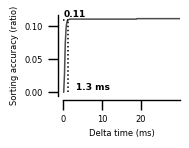

In [3]:
def plot_source_data(df: pd.DataFrame):
    """Sorting accuracy as a function of the delta time; dotted lines: delta time used in the analyses (1.3 ms) and the sorting accuracy at that delta time"""

    from src.nodes.validation import supp_fig6_layout as lay

    fig = lay.new_figure(lay.A_CANVAS)
    ax = lay.add_axes_pt(fig, *lay.A_AXES)
    ax.plot(df["delta_time_ms"], df["sorting_accuracy"], color=(0.3, 0.3, 0.3))

    # delta time used in the analyses and the sorting accuracy at that delta time
    best = df.loc[df["delta_time_ms"] == CHOSEN_DELTA_TIME].iloc[0]
    ax.vlines(x=best["delta_time_ms"], ymin=0, ymax=best["sorting_accuracy"], linestyle=":", color="k")
    ax.hlines(y=best["sorting_accuracy"], xmin=0, xmax=best["delta_time_ms"], linestyle=":", color="k")
    ax.annotate(f"{best['sorting_accuracy']:.2f}", (0, best["sorting_accuracy"] * 1.04), fontweight="bold", fontsize=6.5, annotation_clip=False)
    ax.annotate(f"{best['delta_time_ms']:g} ms", (best["delta_time_ms"] + 2, 0.003), fontweight="bold", fontsize=6.5)

    # disconnect axes (R style)
    ax.spines["bottom"].set_position(("axes", -0.05))
    ax.yaxis.set_ticks_position("left")
    ax.spines["left"].set_position(("axes", -0.05))
    ax.set_xlim((df["delta_time_ms"].min(), df["delta_time_ms"].max()))
    ax.set_xticks([0, 10, 20])
    ax.set_yticks([0, 0.05, 0.10], ["0.00", "0.05", "0.10"])
    ax.set_ylabel("Sorting accuracy (ratio)")
    ax.set_xlabel("Delta time (ms)")
    lay.set_text_sizes(fig)
    return fig, ax


fig, ax = plot_source_data(df)

## Save the figure and the source data

In [4]:
os.makedirs("figures/8_source_data/supp_fig6a", exist_ok=True)
fig.savefig("figures/8_source_data/supp_fig6a/supp_fig6a.svg", bbox_inches="tight", **savefig_cfg)
df.to_excel("figures/8_source_data/supp_fig6a/supp_fig6a.xlsx", index=False)

## Check: replot from the saved source data

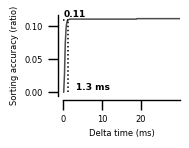

In [5]:
df_loaded = pd.read_excel("figures/8_source_data/supp_fig6a/supp_fig6a.xlsx")
fig, ax = plot_source_data(df_loaded)